In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [43]:
small_label_settings = {
    'font.family': 'Arial',
    'font.size': 7,              # base font size
    'xtick.labelsize': 5,        # x-axis tick label size
    'ytick.labelsize': 5,        # y-axis tick label size
    'axes.labelsize': 7,         # axis label size
    'axes.titlesize': 7,         # title size
    'legend.fontsize': 7,        # legend font size
    'figure.titlesize': 7        # figure title size
}

In [44]:
experiment = 'full_pipeline'
file = f'../experiments/{experiment}/final_data.csv'

In [45]:
df = pd.read_csv(file)

# Remove controls
df = df[~df['fish'].str.contains('ctrl', case=False, na=False)]

In [46]:
df[df['sample'] == 1]

,barcode,fish,sample,replicate,file,reads,proportion
0,12D+34_12D+60_NONE_NONE_3D+143_84D+169_84D+169...,fish1,1,1,fish1_s1_rep1,57559,0.750512
1,12D+34_12D+60_NONE_NONE_NONE_NONE_54D+199_54D+...,fish1,1,1,fish1_s1_rep1,643,0.008384
2,1D+38_28D+41_NONE_18D+113_NONE_NONE_54D+199_54...,fish1,1,1,fish1_s1_rep1,1345,0.017537
3,1D+38_28D+41_NONE_NONE_NONE_NONE_54D+199_54D+1...,fish1,1,1,fish1_s1_rep1,10646,0.138813
4,1D+38_28D+41_NONE_NONE_NONE_NONE_NONE_NONE_NON...,fish1,1,1,fish1_s1_rep1,792,0.010327
...,...,...,...,...,...,...,...
5090,2I+39+AG_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NO...,fish8,1,3,fish8_s1_rep3,9674,0.188831
5091,3D+35_27D+51_50D+86_50D+86_NONE_NONE_NONE_NONE...,fish8,1,3,fish8_s1_rep3,1740,0.033964
5092,3D+35_27D+51_NONE_NONE_NONE_NONE_54D+199_54D+1...,fish8,1,3,fish8_s1_rep3,3340,0.065195
5093,3D+35_27D+51_NONE_NONE_NONE_NONE_NONE_NONE_NON...,fish8,1,3,fish8_s1_rep3,10056,0.196287


In [47]:
barcode_counts = df.groupby(['fish', 'sample'], as_index = False).agg({'barcode': 'nunique'})

In [53]:
model = smf.mixedlm(
    "barcode ~ sample",
    data=barcode_counts,
    groups=barcode_counts["fish"],
    re_formula="~sample"   # random intercept + random slope
)
result = model.fit()
print(result.summary())

            Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   barcode  
No. Observations:   235       Method:               REML     
No. Groups:         24        Scale:                2.3729   
Min. group size:    3         Log-Likelihood:       -495.8080
Max. group size:    16        Converged:            Yes      
Mean group size:    9.8                                      
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           9.705    0.896 10.836 0.000  7.950 11.461
sample             -0.112    0.061 -1.829 0.067 -0.233  0.008
Group Var          17.583    3.827                           
Group x sample Cov -0.567    0.194                           
sample Var          0.051    0.017                           



In [49]:
# Fixed effects (shared across all groups)
fixed_effects = result.fe_params  

# Random effects (group-specific deviations)
random_effects = result.random_effects

In [50]:
import pandas as pd

lines = {
    group: {
        "intercept": fixed_effects["Intercept"] + re.get("Intercept", re.get("Group", 0)),
        "slope": fixed_effects["sample"] + re.get("sample", 0)
    }
    for group, re in random_effects.items()
}

lines_df = pd.DataFrame.from_dict(lines, orient="index")
print(lines_df)

        intercept     slope
fish1    8.607568 -0.095413
fish10   2.195117 -0.063109
fish12  15.084146 -0.463447
fish13  14.932054 -0.215514
fish14  14.803744 -0.342517
fish15   8.596480 -0.094830
fish16  14.764218 -0.189967
fish17  14.312663 -0.397120
fish18   6.095248 -0.111681
fish2    3.519042  0.028673
fish22   9.051968 -0.162126
fish26  11.501901 -0.179938
fish35  15.469685  0.063351
fish37   9.717593 -0.151851
fish38  15.115288 -0.465966
fish4    6.579492  0.023348
fish40   6.590433  0.120041
fish42   9.093988  0.018787
fish44   6.933309  0.052555
fish45   3.308983  0.023056
fish5    8.037030 -0.207437
fish50   9.599882 -0.082154
fish51   8.271993  0.274949
fish8   10.749341 -0.075958


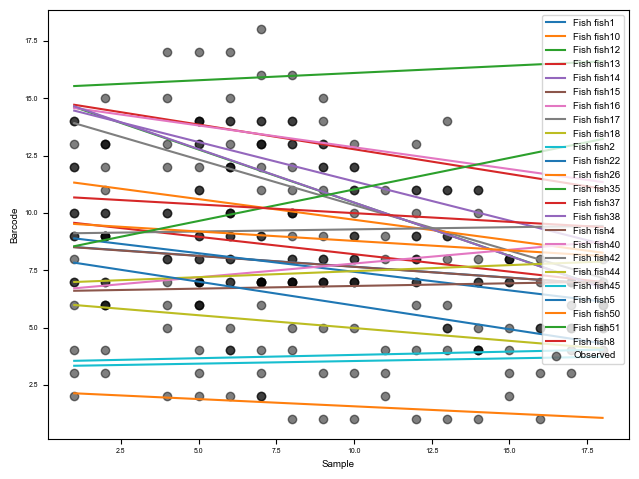

In [51]:
import matplotlib.pyplot as plt
import numpy as np

# Shared x-axis range
x_vals = np.linspace(barcode_counts["sample"].min(),
                     barcode_counts["sample"].max(), 100)

# Plot fitted line for each group
for group, re in random_effects.items():
    intercept = fixed_effects["Intercept"] + re.get("Intercept", re.get("Group", 0))
    slope = fixed_effects["sample"] + re.get("sample", 0)
    y_vals = intercept + slope * x_vals
    plt.plot(x_vals, y_vals, label=f"Fish {group}")

# Scatterplot of raw data
plt.scatter(barcode_counts["sample"], barcode_counts["barcode"],
            alpha=0.5, color="black", label="Observed")

# Labels and legend
plt.xlabel("Sample")
plt.ylabel("Barcode")
plt.legend()
plt.tight_layout()
plt.show()

/var/folders/59/35nb2tq50vz3vpwjkwkzppvh0000gn/T/ipykernel_4598/4178839506.py:36: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


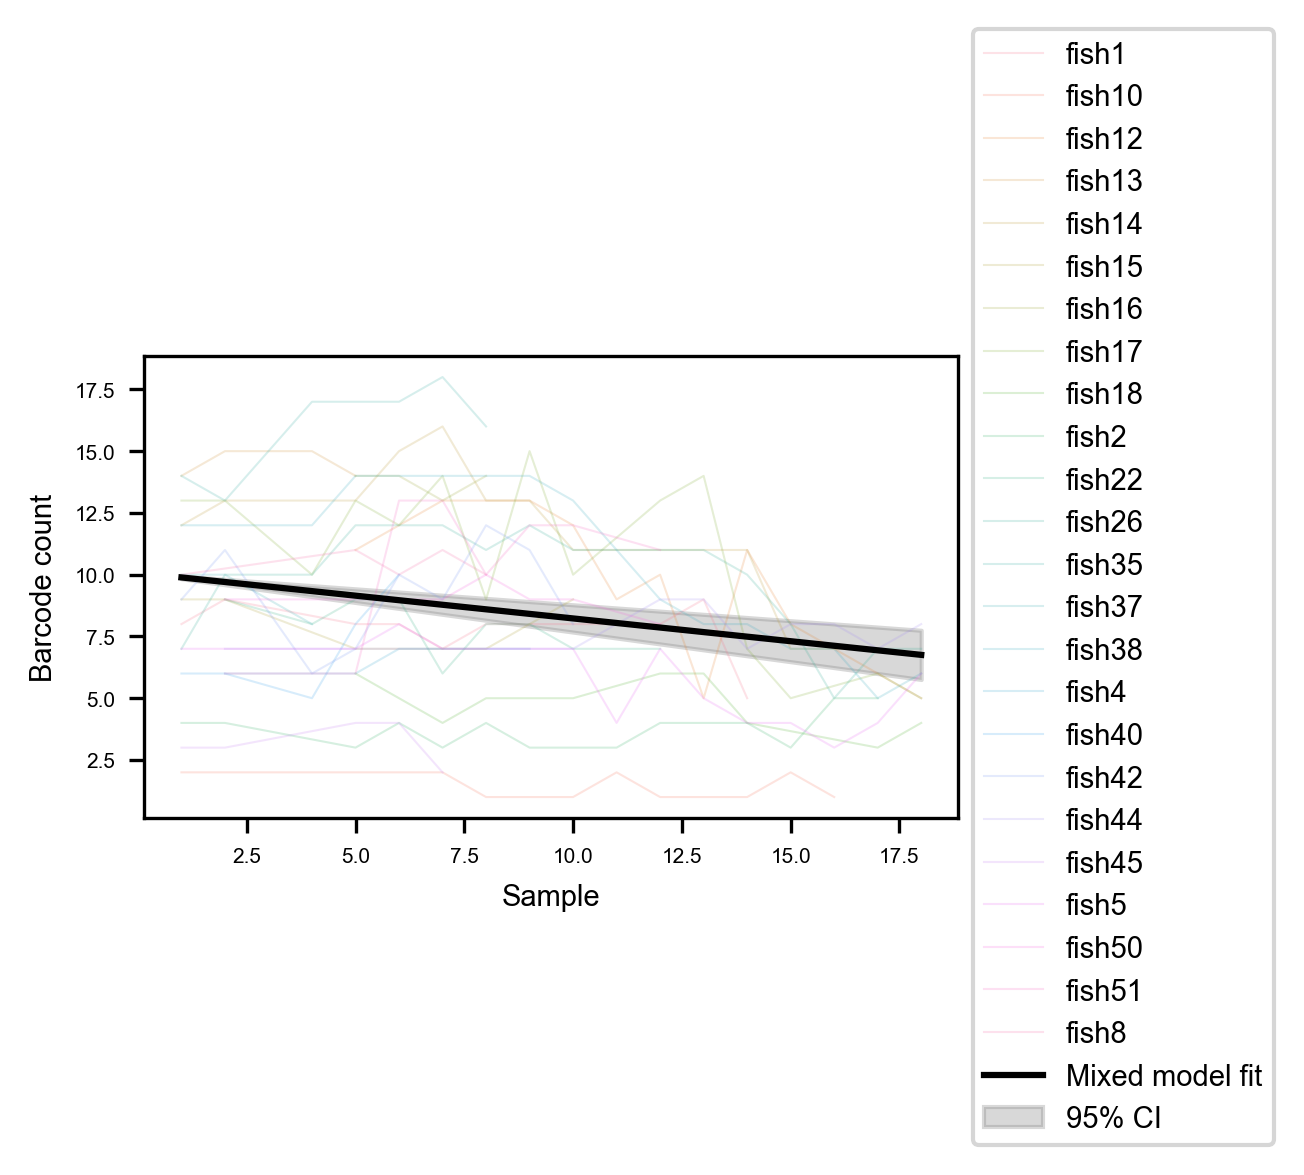

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import numpy as np

# Fit mixed model
model = smf.mixedlm("barcode ~ sample", barcode_counts, groups=barcode_counts["fish"])
result = model.fit()

# Extract fixed effect slope and intercept
intercept = result.params['Intercept']
slope = result.params['sample']

plt.style.use('default')
plt.rcParams.update(small_label_settings)

# Plot spaghetti lines per fish
plt.figure(figsize=(3.5, 2), dpi=300)
sns.lineplot(data=barcode_counts, x="sample", y="barcode", hue="fish",
             estimator=None, alpha=0.2, linewidth=0.5)

# Overlay fitted regression line
x_vals = np.linspace(barcode_counts['sample'].min(), barcode_counts['sample'].max(), 100)
y_vals = intercept + slope * x_vals
plt.plot(x_vals, y_vals, color="black", linewidth=1.5, label="Mixed model fit")

# Confidence band (approximate using standard error of slope)
se_slope = result.bse['sample']
y_lower = intercept + (slope - 1.96*se_slope) * x_vals
y_upper = intercept + (slope + 1.96*se_slope) * x_vals
plt.fill_between(x_vals, y_lower, y_upper, color="gray", alpha=0.3, label="95% CI")

plt.xlabel("Sample")
plt.ylabel("Barcode count")
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()